# 양서연 · 악천후 통행시간 곡선과 도로 군집 분석

최신 **Train·Dev 결과만** 읽는다. Test 시즌은 열지 않는다. 통행시간 비율 곡선을 주 군집으로 사용하고 교통량 변화는 보조 해석으로 사용한다.

In [1]:
# [서연] 조회 전용 환경 — 분석을 자동 실행하지 않는다.
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
RUN_BUILD = False
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'README.md').exists() and (p / '.git').exists())
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures' / 'ysy'
LOGS = ROOT / 'logs' / 'ysy' / 'traffic_analysis'
print('저장소:', ROOT)
print('RUN_BUILD:', RUN_BUILD, '(기존 결과만 조회)')

저장소: C:\Users\USER\seoul-weather-traffic
RUN_BUILD: False (기존 결과만 조회)


In [2]:
# [서연] 수정 후 최신 군집 결과
analysis_log = sorted(LOGS.glob('traffic_analysis_*_(성공)_v*.json'))[-1]
report = json.loads(analysis_log.read_text(encoding='utf-8'))
display(pd.DataFrame([{'입력 행': report['rows']['source'], '도로': report['rows']['train_roads'], '유효 쌍': report['pairing']['valid_pairs'], '최적 k': report['clustering']['best_k'], '실루엣': report['clustering']['silhouette_scores'][str(report['clustering']['best_k'])], 'Train 도로': report['clustering']['clustered_roads'], 'Dev 도로': report['clustering']['dev_clustered_roads'], 'Dev 미분류': report['clustering']['dev_unclustered_roads'], 'Train·Dev 일치율': report['clustering']['train_dev_cluster_agreement_rate'], 'Test 제외': report.get('excluded_model_set') == 'test'}]))
print('최신 로그:', analysis_log.name)

,입력 행,도로,유효 쌍,최적 k,실루엣,Train 도로,Dev 도로,Dev 미분류,Train·Dev 일치율,Test 제외
0,50400,52,19037,6,0.322581,52,51,1,0.254902,True


최신 로그: traffic_analysis_20261127T213020_(성공)_v01.json


### 수정 및 실패 분석

기존 `decrease_share = values.lt(0).mean()`은 결측을 ‘감소하지 않음’으로 포함했다. 104개 도로×분할 특징 중 40개가 영향을 받았고 최대 차이는 0.711이었다. 결측을 분모에서 제외하도록 수정했다. 수정 후에도 군집 안정성이 낮으므로 수집 오류가 아니라 표본 수·관측률·계절별 반응 차이의 영향도 크다고 판단한다.

In [3]:
# [서연] 주 분석: 도로·방향 통행시간 비율 곡선 K-means·DTW
curve_log = sorted(LOGS.glob('traffic_travel_curve_clustering_*_(성공)_v*.json'))[-1]
curve_report = json.loads(curve_log.read_text(encoding='utf-8'))
curve_clusters = pd.read_csv(sorted(TABLES.glob('yang_seoyeon_travel_curve_clusters_*_(성공)_v*.csv'))[-1], encoding='utf-8-sig')
curve_scores = pd.read_csv(sorted(TABLES.glob('yang_seoyeon_travel_curve_scores_*_(성공)_v*.csv'))[-1], encoding='utf-8-sig')
display(pd.DataFrame(curve_report['scope_reports']).T)
display(curve_scores)
display(curve_clusters.groupby(['weather_scope', 'model_set', 'kmeans_cluster'], dropna=False).size().rename('도로·방향 수').reset_index())
print('통행시간 곡선이 주 군집이며 교통량 변화율은 보조 해석에만 사용합니다. Test 제외:', curve_report['test_excluded'])

,status,interpretation_status,selected_k,dtw_status,dtw_selected_k,train_eligible,dev_eligible,comparable,same_cluster,agreement_rate,train_cluster_sizes,dtw_comparable,dtw_same_cluster,dtw_agreement_rate,dtw_train_cluster_sizes,kmeans_dtw_ari_train,selection_rule,dtw_selection_rule,observations
all,성공,주 분석 사용,3,소군집으로 제외,None,180,180,180,140,0.777778,"{'0': 45, '1': 115, '2': 20}",0,0,None,{},None,k=3 기본; k=2~6 실루엣·inertia·최소 군집 크기를 함께 보고,k=2~6 중 최소 군집 5개 이상인 후보에서 실루엣 최대,"{'dev': {'events': 21, 'dates': 28, 'hours': 1..."
snow,성공,불안정_해석보류,3,소군집으로 제외,None,180,180,180,55,0.305556,"{'0': 40, '1': 31, '2': 109}",0,0,None,{},None,k=3 기본; k=2~6 실루엣·inertia·최소 군집 크기를 함께 보고,k=2~6 중 최소 군집 5개 이상인 후보에서 실루엣 최대,"{'dev': {'events': 6, 'dates': 7, 'hours': 521..."
rain,성공,주 분석 사용,3,소군집으로 제외,None,180,180,180,114,0.633333,"{'0': 50, '1': 37, '2': 93}",0,0,None,{},None,k=3 기본; k=2~6 실루엣·inertia·최소 군집 크기를 함께 보고,k=2~6 중 최소 군집 5개 이상인 후보에서 실루엣 최대,"{'dev': {'events': 15, 'dates': 21, 'hours': 1..."


,weather_scope,method,k,silhouette,inertia,min_cluster_size,dev_comparable,dev_same_cluster,dev_agreement_rate
0,all,kmeans,2,0.293599,685.957051,54,180,144,0.800000
1,all,kmeans,3,0.290653,551.665049,20,180,140,0.777778
2,all,kmeans,4,0.283295,451.358065,12,180,124,0.688889
3,all,kmeans,5,0.267216,391.061480,7,180,115,0.638889
4,all,kmeans,6,0.272272,355.676286,2,180,117,0.650000
5,all,dtw,2,0.654907,NaN,2,180,178,0.988889
6,all,dtw,3,0.637685,NaN,1,180,178,0.988889
7,all,dtw,4,0.517284,NaN,1,180,161,0.894444
8,all,dtw,5,0.447473,NaN,1,180,158,0.877778
9,all,dtw,6,0.361787,NaN,1,180,157,0.872222


,weather_scope,model_set,kmeans_cluster,도로·방향 수
0,all,dev,0,46
1,all,dev,1,114
2,all,dev,2,20
3,all,train,0,45
4,all,train,1,115
5,all,train,2,20
6,rain,dev,0,38
7,rain,dev,1,70
8,rain,dev,2,72
9,rain,train,0,50


통행시간 곡선이 주 군집이며 교통량 변화율은 보조 해석에만 사용합니다. Test 제외: True


In [4]:
# [서연] 노션 확정 기준의 링크 Gi*와 맑은 시간 Isolation Forest 결과
gi = pd.read_csv(sorted(TABLES.glob('yang_seoyeon_gi_link_hotspots_*_(성공)_v02.csv'))[-1], encoding='utf-8-sig')
anomaly = pd.read_csv(sorted(TABLES.glob('yang_seoyeon_anomaly_clear_summary_*_(성공)_v02.csv'))[-1], encoding='utf-8-sig')
display(gi.groupby(['model_set', 'hotspot_status']).size().rename('링크 수').reset_index())
display(anomaly)
print('Gi*: 링크 단위 500m 이웃·BH-FDR. Isolation Forest: 맑은 시간·과거 28일 입력용 평소값. Test 제외.')

,model_set,hotspot_status,링크 수
0,dev,cold,41
1,dev,hot,2
2,dev,not_significant,1710
3,train,cold,63
4,train,hot,17
5,train,not_significant,1673


,model_set,rows,valid,anomalies,dates,roads
0,dev,133020,117407,5186,164,90
1,train,279180,246749,12339,336,90


Gi*: 링크 단위 500m 이웃·BH-FDR. Isolation Forest: 맑은 시간·과거 28일 입력용 평소값. Test 제외.


In [5]:
# [서연] 뉴스 연결 결과
news_log = sorted(LOGS.glob('traffic_news_join_*_(성공)_v*.json'))[-1]
news_report = json.loads(news_log.read_text(encoding='utf-8'))
display(pd.DataFrame([{'뉴스 후보': news_report['news_candidates'], '교통 자료 연결': news_report['traffic_matched'], '분석 후보': news_report['eligible_candidates'], '고유 기사': news_report['eligible_unique_articles']}]))
print(news_report['limitations'])

,뉴스 후보,교통 자료 연결,분석 후보,고유 기사
0,335,324,59,34


제목 기반 검토 후보만 연결; 사건일·시간·원인 미확인. 뉴스는 학습에 사용하지 않음. 도로·날짜별 중앙값은 관측 출퇴근 시간에 한정.


In [6]:
# [서연] 대표 사례 5건 — 수동 검토 우선순위
case_path = sorted(TABLES.glob('yang_seoyeon_representative_cases_*_(성공)_v*.csv'))[-1]
cases = pd.read_csv(case_path, encoding='utf-8-sig')
show = ['representative_order', 'split', 'event_date', 'road_id', 'road_name', 'hour', 'case_type', 'anomaly_score', 'volume_change_pct_median', 'travel_time_change_pct_median', 'evidence_level', 'representative_title', 'manual_review_status']
display(cases[show])
print('기사 본문·실제 사건 시각·통제 여부·인과관계는 자동 확정하지 않았다.')

,representative_order,split,event_date,road_id,road_name,hour,case_type,anomaly_score,volume_change_pct_median,travel_time_change_pct_median,evidence_level,representative_title,manual_review_status
0,1,train,2024-07-17,R006,동부간선도로,9,통행시간 급증·교통량 감소,0.610629,-22.566372,54.045445,뉴스·통제표현 후보 있음,수도권 폭우로 출근길 대혼잡 우려..동부간선도로 통제,기사 본문·사건일·실제 통제·인과관계 미확인
1,2,dev,2024-11-27,R075,종로,20,통행시간 감소·교통량 감소,0.603274,-18.334656,-33.944505,뉴스 제목 후보 있음,"오세훈, 종로 부암동 찾아 '폭설 출근길' 제설작업 점검",기사 본문·사건일·실제 통제·인과관계 미확인
2,3,train,2024-07-17,R005,내부순환로,9,통행시간 급증·교통량 감소,0.580393,-12.247113,53.587576,뉴스·통제표현 후보 있음,집중호우에 서울 동부간선도로·내부순환로 교통 통제,기사 본문·사건일·실제 통제·인과관계 미확인
3,4,train,2024-02-20,R009,서부간선지하도로,19,통행시간 급증,0.670237,16.709341,201.061716,수치 이상만 확인,NaN,기사 본문·사건일·실제 통제·인과관계 미확인
4,5,train,2024-02-22,R003,경부고속도로,19,복합 이상,0.649146,20.475621,-47.779845,수치 이상만 확인,NaN,기사 본문·사건일·실제 통제·인과관계 미확인


기사 본문·실제 사건 시각·통제 여부·인과관계는 자동 확정하지 않았다.


In [7]:
# [서연] 최소 군집 크기·관측률 민감도
sensitivity_path = sorted(TABLES.glob('yang_seoyeon_cluster_sensitivity_selected_*_(성공)_v*.csv'))[-1]
cluster_sensitivity = pd.read_csv(sensitivity_path, encoding='utf-8-sig')
display(cluster_sensitivity[['coverage_rule', 'k', 'silhouette', 'train_roads', 'dev_roads', 'train_min_cluster_size', 'comparable_roads', 'same_cluster_roads', 'agreement_rate', 'excluded_road_hours']])
print('관측률과 최소 군집 크기를 바꿔도 낮은 일치율이 유지되는지 확인한 실패 원인 분석이다.')

,coverage_rule,k,silhouette,train_roads,dev_roads,train_min_cluster_size,comparable_roads,same_cluster_roads,agreement_rate,excluded_road_hours
0,전체,4,0.296314,52,51,5,51,14,0.274510,0
1,관측률_50%이상,2,0.304748,52,51,14,51,17,0.333333,195
2,관측률_100%,2,0.381554,51,42,11,42,14,0.333333,2263


관측률과 최소 군집 크기를 바꿔도 낮은 일치율이 유지되는지 확인한 실패 원인 분석이다.


travel_curve_clusters_20261127T215237041158_(성공)_v01.png


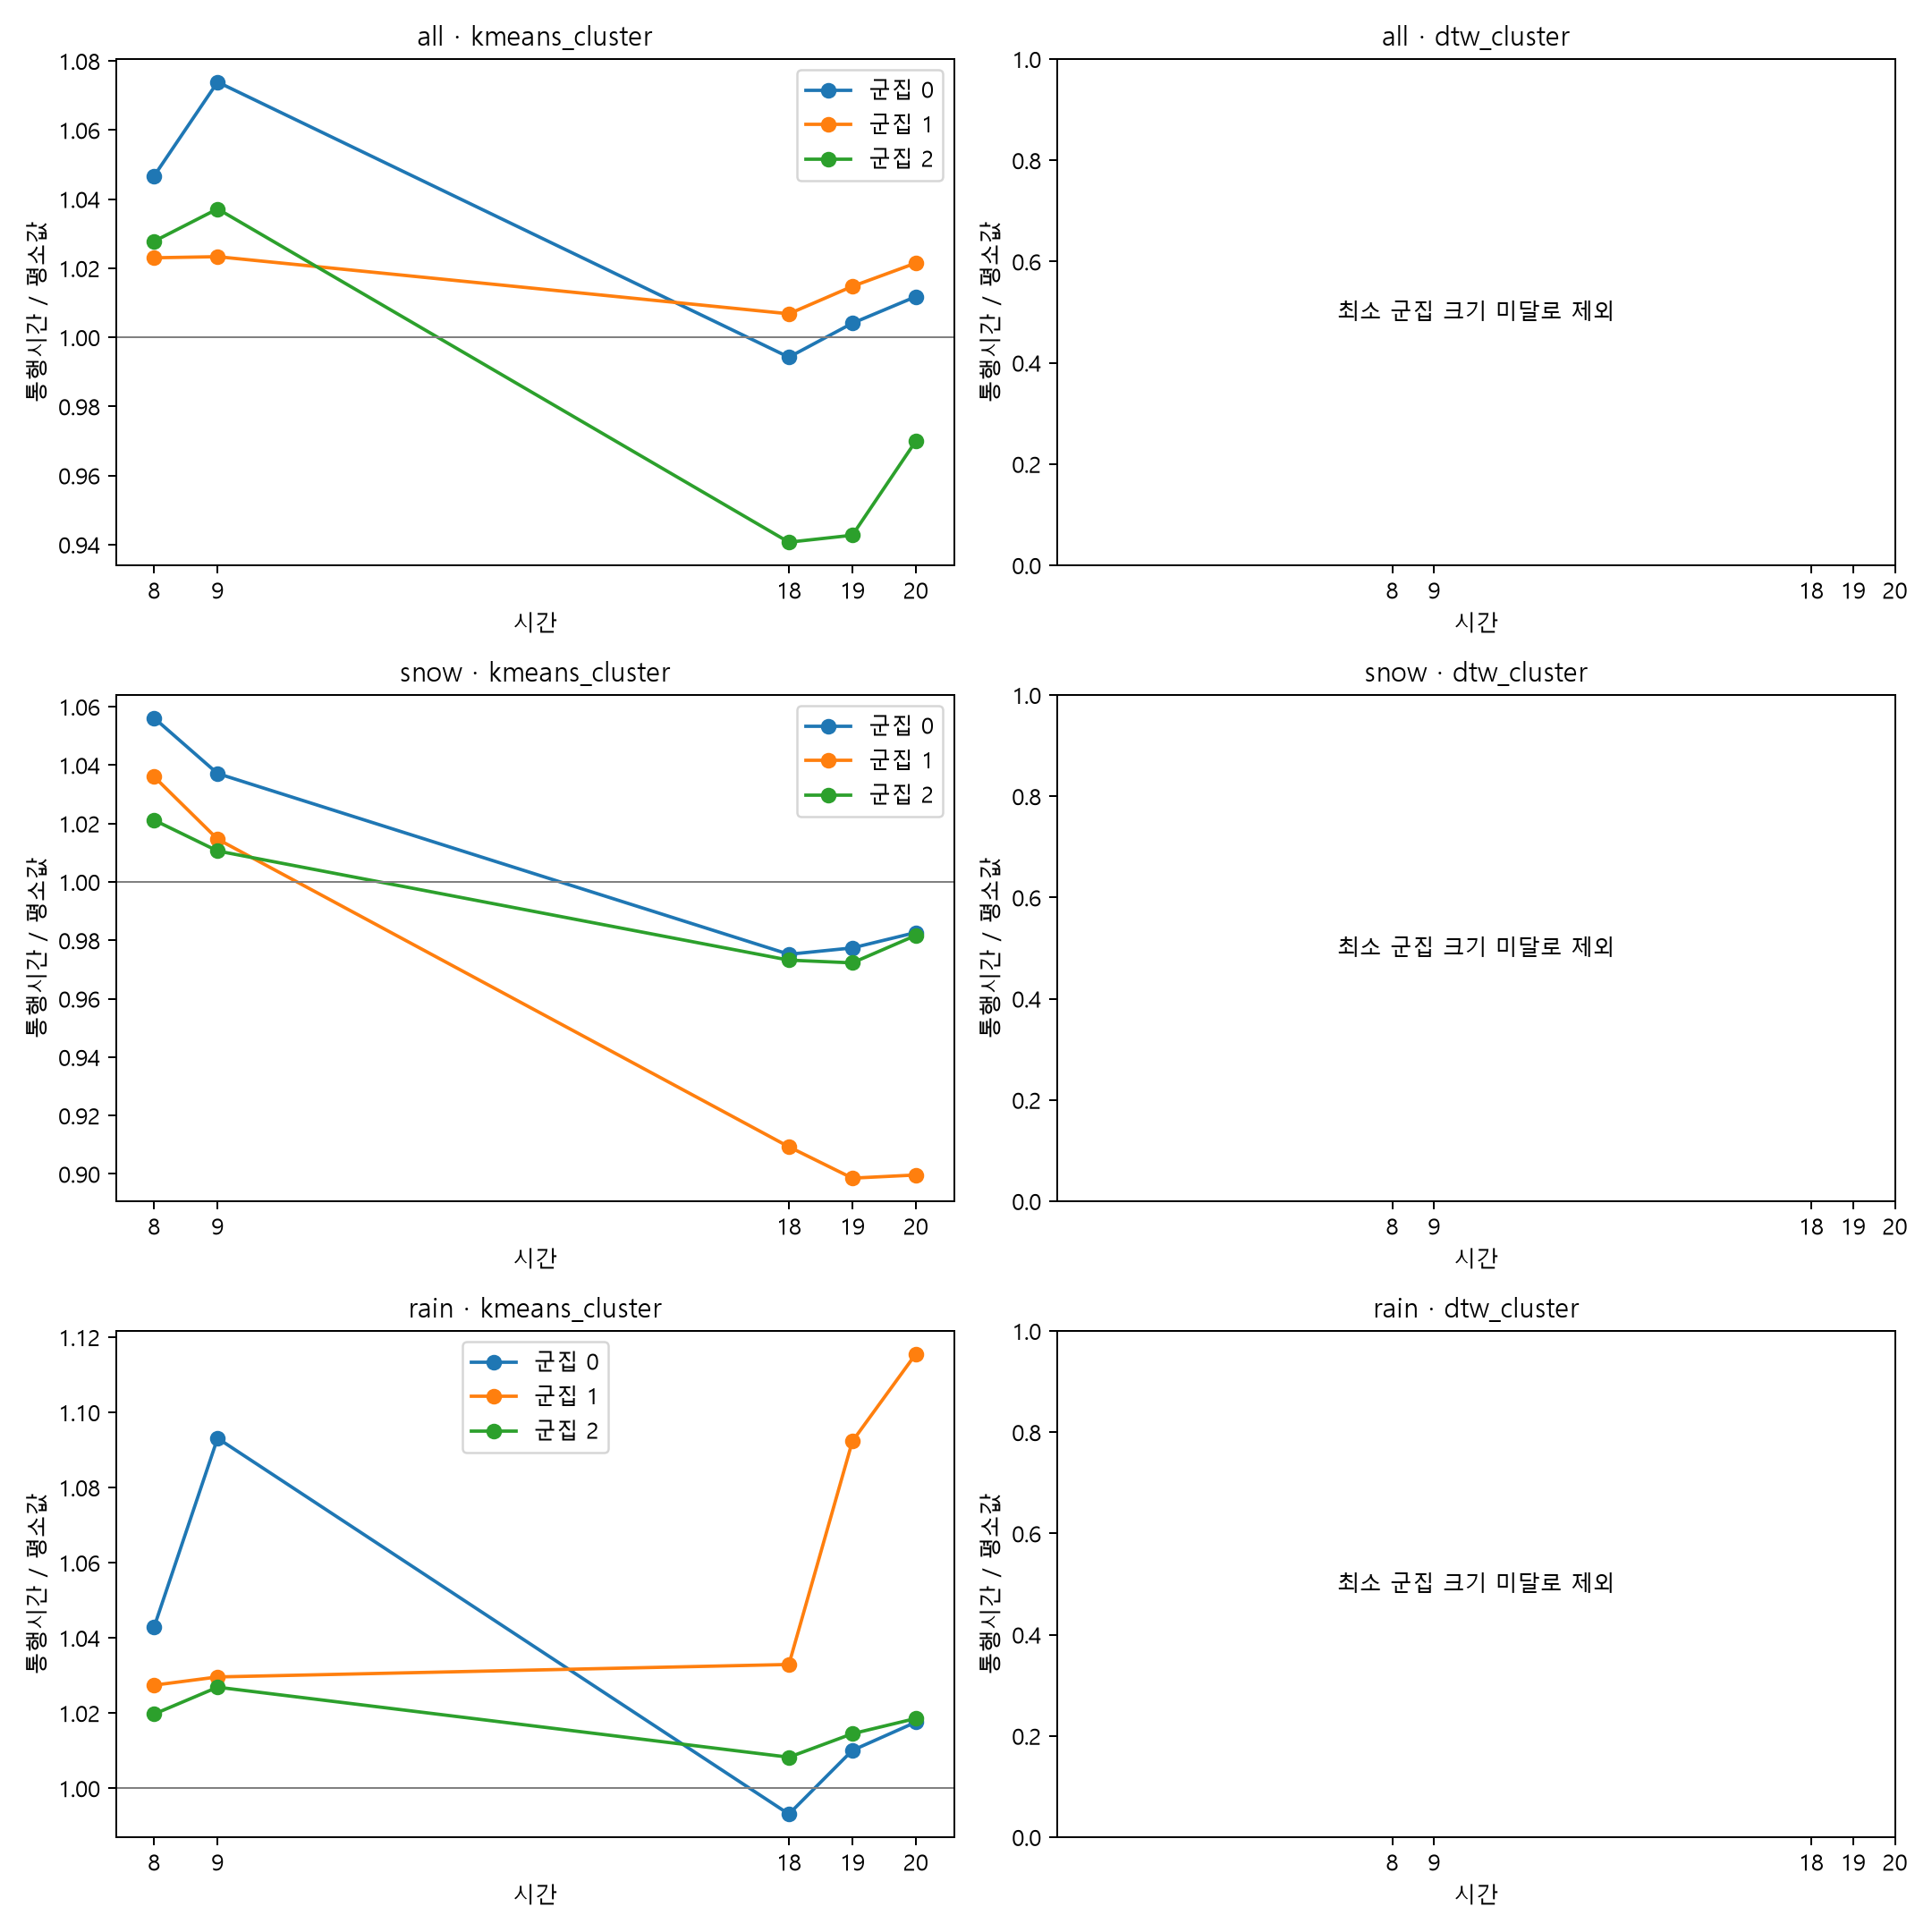

gi_link_hotspots_20261127T213200974578_(성공)_v02.png


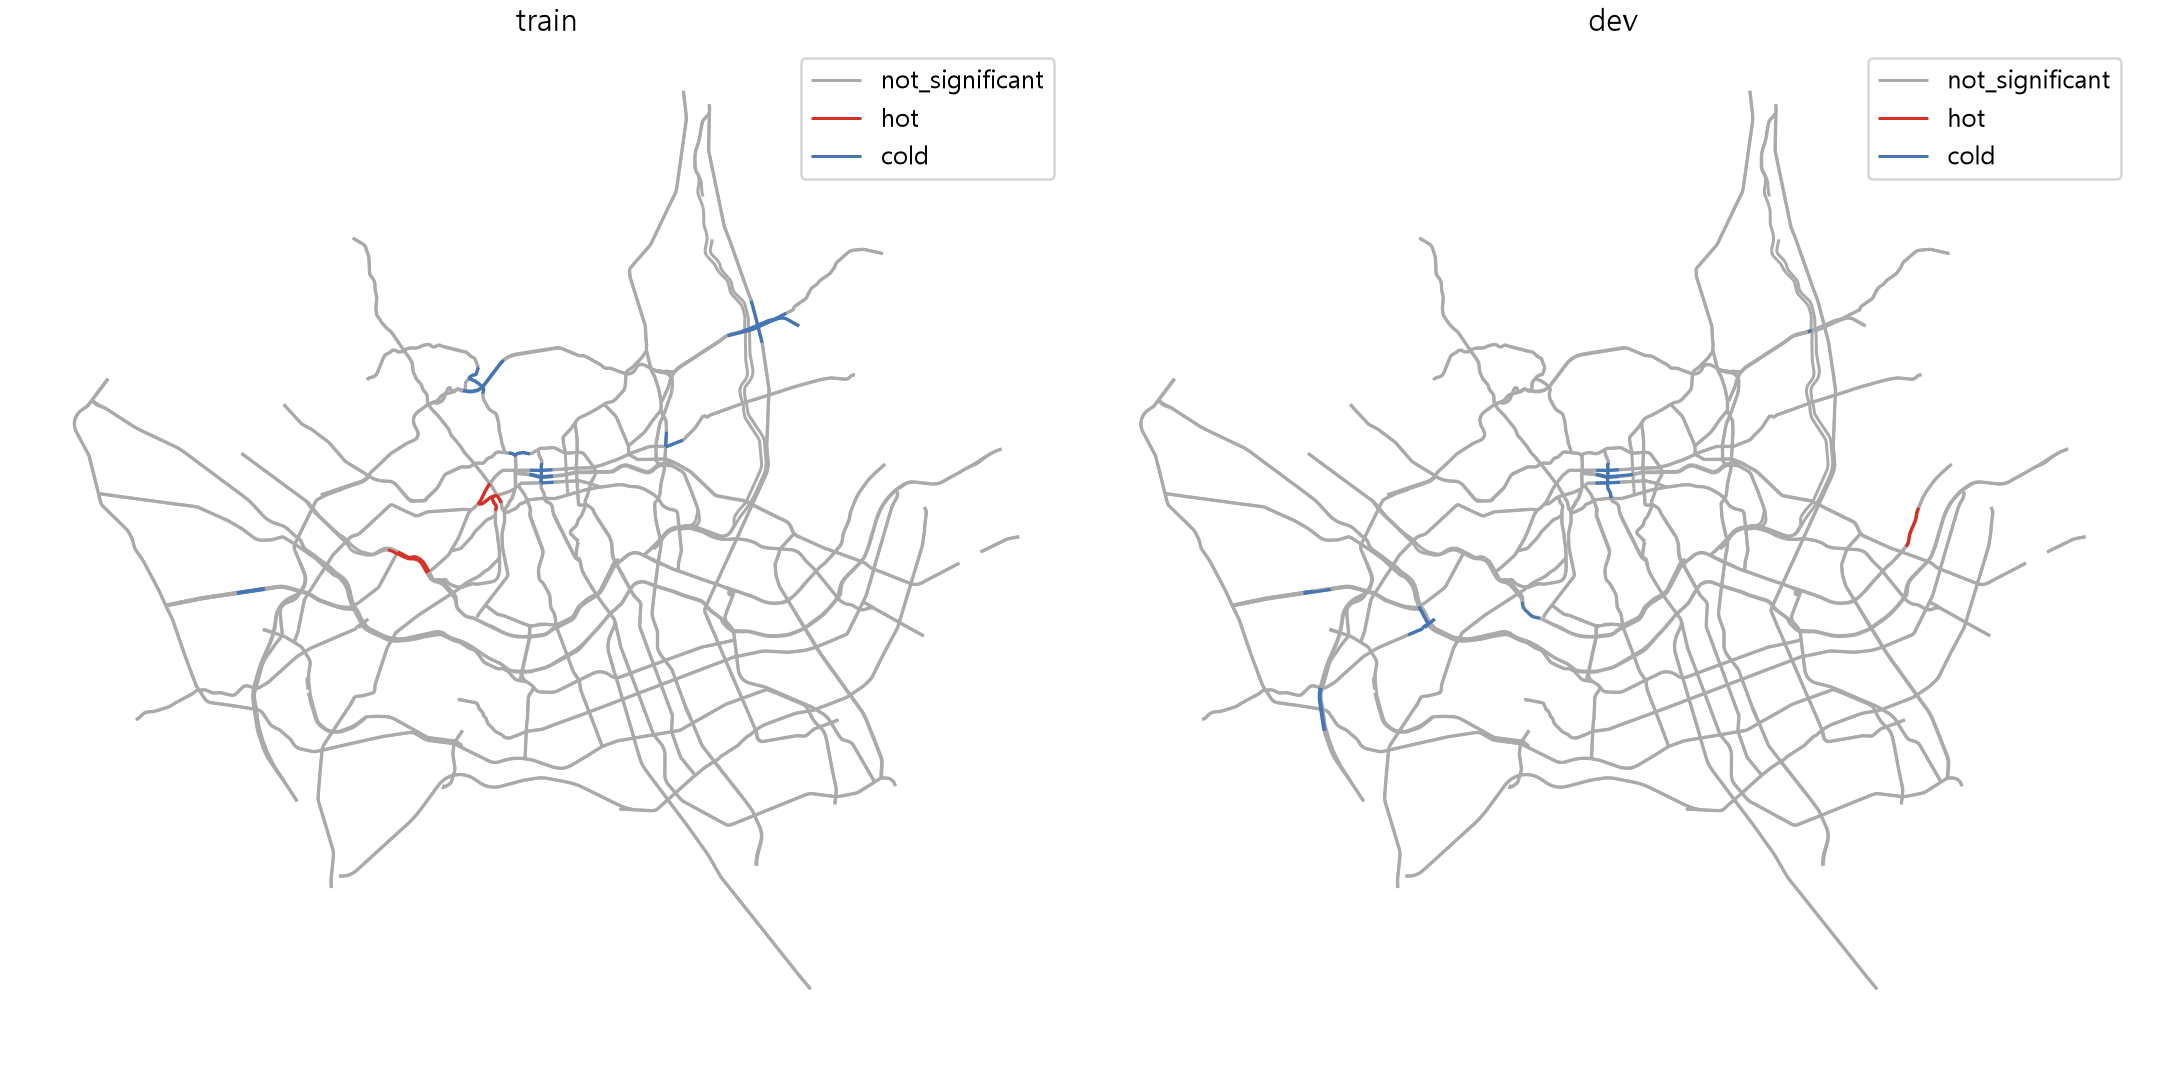

In [8]:
# [서연] 최신 핵심 그림
patterns = ['travel_curve_clusters_*_(성공)_v*.png', 'gi_link_hotspots_*_(성공)_v*.png']
for pattern in patterns:
    path = sorted(FIGURES.glob(pattern))[-1]
    print(path.name)
    display(Image(filename=str(path), width=850))